# Khmer TTS Step 4: Evaluation
**Group 5, ITM 454 Natural Language Processing**

**Input:** the fine-tuned VITS checkpoint from Step 3 (`best_model.pth` + `config.json`) and the test split from Step 2 (`processed/metadata_test.csv` + `processed/wavs/`).
**Output:** everything is saved in `NLPfinalproject/step4_evaluation/` (audio, transcripts, metric tables, figures, and the MOS listening-test package).

| Part | What | Metric (from the proposal) |
|---|---|---|
| A | Generate speech for the 399 test sentences and the out-of-domain sentences, using **our VITS** and a **baseline** (Meta MMS-TTS Khmer) | – |
| B | Transcribe all audio with a Khmer ASR model (`seanghay/Qwen3-ASR-0.6B-Khmer`) and compare it with the input text | **CER** |
| C | Compare synthetic audio with the real recordings | **MCD**, duration ratio, real-time factor |
| D | Build a blind listening test, then analyse the ratings | **MOS** (ITU-T P.800, 1–5) |
| E | Find where and why the model fails | CER by topic and length, character errors |
| F | One summary table and findings for the report | – |

**Three systems are compared.**
- **Real recordings** are the *topline*. Their CER shows how much error comes from the ASR model alone.
- **Ours** is the fine-tuned VITS model.
- **MMS-TTS Khmer** (`facebook/mms-tts-khm`) is an existing public Khmer VITS model, used as the *baseline*.

**Run order.**
1. Use **Runtime → Change runtime type → T4 GPU**.
2. Run the **Setup** cell, then the parts in order. **Runtime → Run all** works too: there is no restart anywhere.
3. Every slow step skips files it has already made, so you can stop and re-run safely. Part A's audio is already saved on Drive, so re-running Part A takes only seconds.


> **Note (2 Nov 2026):** this is the executed evaluation run (all cells ran without errors). After the run, the MCD code in Part C was corrected to use the log *power* spectrum, as in `pysptk.sp2mc`. That makes every MCD value exactly 2× the old one. The outputs of Part C and Part F were cleared because they showed the old scale. The corrected numbers are in `results/` (MCD: ours 4.90 dB, MMS 7.30 dB). Re-running Setup → Part C → Part F reproduces them.

## Setup
**All settings are in the next cell**: paths, evaluation settings and `OOD_SENTENCES`. Run it first in every new Colab session.

### Mount Drive and set paths
`NLPfinalproject` is a *shared* folder. If it is not found, open Drive, right-click the folder, choose **Organize → Add shortcut → My Drive**, then run this cell again.

**Files Step 4 needs on Drive:**
- `processed/metadata_test.csv` and the **399 test wavs** in `processed/wavs/` (only the test clips are needed, about 0.9 h)
- `processed/dataset_final.csv` (optional, used for topics)
- the Step 3 training run folder with `best_model.pth` and `config.json`

### Packages and shared helpers
`clean_khmer` is the **same function as in Step 1**, so new sentences are cleaned the same way as the training text.

For **CER**, both texts are normalised first: NFC form, then spaces, zero-width characters and punctuation (`។ ៕ ៖ , . ? ! " '`) are removed. Khmer has no word spaces, and the ASR model writes no punctuation, so they should not count as errors. The repeat mark `ៗ` is kept because it is spoken. `ឲ` and `ឱ` are two spellings of the same vowel, so they count as the same letter. CER is counted in Unicode code points.

### Load the test set and the out-of-domain sentences
**In-domain** means the 399 held-out test sentences from Step 2 (same cultural topics as training, but unseen paragraphs).
**Out-of-domain (OOD)** means everyday sentences that are not about the dataset's topics. They have no real recording, so they get CER and MOS but no MCD.
➡️ **Replace `OOD_SENTENCES` with the out-of-domain sentences used in Step 3**, so the results match the samples already generated.

In [12]:
# ================= Step 4 setup =================
# Edit paths, settings and OOD_SENTENCES here. Every part below uses these values.

from google.colab import drive
drive.mount('/content/drive')

import os, glob
from pathlib import Path

# ---------- paths (change these only if auto-search fails) ----------
PROJECT_DIR = None   # e.g. '/content/drive/MyDrive/NLPfinalproject'
RUN_DIR     = None   # e.g. '/content/drive/MyDrive/NLPfinalproject/runs/vits_khmer-October-25-2026_10+00AM-abc123'

if PROJECT_DIR is None:
    patterns = ['/content/drive/MyDrive/NLPfinalproject',
                '/content/drive/MyDrive/*/NLPfinalproject',
                '/content/drive/MyDrive/*/*/NLPfinalproject',
                '/content/drive/Shareddrives/*/NLPfinalproject']
    hits = [p for pat in patterns for p in glob.glob(pat)]
    assert hits, "NLPfinalproject not found: add a shortcut to it in My Drive, or set PROJECT_DIR."
    PROJECT_DIR = hits[0]
PROJECT_DIR = Path(PROJECT_DIR)
PROC_DIR    = PROJECT_DIR / 'processed'
EVAL_DIR    = PROJECT_DIR / 'step4_evaluation'

def find_files(root, name, max_depth=5, skip=('wavs', 'step4_evaluation', '.git')):
    # walk the Drive without entering big audio folders
    root = Path(root); found = []
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        dirnames[:] = [d for d in dirnames if d not in skip and depth < max_depth]
        found += [Path(dirpath) / f for f in filenames if f == name]
    return sorted(found, key=lambda p: p.stat().st_mtime, reverse=True)

if RUN_DIR is None:
    ckpts = find_files(PROJECT_DIR, 'best_model.pth') or find_files('/content/drive/MyDrive', 'best_model.pth', max_depth=4)
    assert ckpts, "No best_model.pth found. Set RUN_DIR to the Step 3 training output folder."
    RUN_DIR = ckpts[0].parent
RUN_DIR = Path(RUN_DIR)
CKPT, CONFIG = RUN_DIR / 'best_model.pth', RUN_DIR / 'config.json'

# ---------- settings ----------
ASR_MODEL      = 'seanghay/Qwen3-ASR-0.6B-Khmer'   # Khmer ASR used for CER (named in the proposal)
BASELINE_MODEL = 'facebook/mms-tts-khm'            # public Khmer VITS used as the baseline
EVAL_SR  = 22050      # every metric is computed at the training sample rate
N_TEST   = None       # None = all test sentences; e.g. 20 for a quick dry run
N_MOS_IN = 15         # in-domain sentences in the listening test (x3 systems)
SEED     = 42

D = {k: EVAL_DIR / k for k in ['audio', 'transcripts', 'results', 'figures', 'mos']}
for p in D.values(): p.mkdir(parents=True, exist_ok=True)

for name, p in [('project', PROJECT_DIR), ('processed', PROC_DIR), ('checkpoint', CKPT), ('config', CONFIG)]:
    print(f"{'OK ' if p.exists() else 'MISSING'}  {name:10s} {p}")

!pip -q install rapidfuzz pyloudnorm

import re, json, time, random, unicodedata, contextlib, io, zipfile, warnings
import numpy as np, pandas as pd, soundfile as sf, librosa, librosa.display, scipy
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import Audio, display, Markdown
from rapidfuzz.distance import Levenshtein
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
random.seed(SEED); np.random.seed(SEED)

# ---- Step 1 text cleaning (identical) ----
ZW = dict.fromkeys(map(ord, "\u200b\u200c\u200d\ufeff"), None)
def clean_khmer(t: str) -> str:
    t = unicodedata.normalize("NFC", t)
    t = t.translate(ZW)
    t = t.replace("៕", "។")
    t = re.sub(r"[\"“”«»‘’()\[\]{}]", " ", t)
    t = t.replace("–", " ").replace("-", " ").replace(":", " ").replace("៖", " ").replace("/", " ")
    t = re.sub(r"[\s\u00a0]+", " ", t)
    t = re.sub(r"\s+([។?!,])", r"\1", t)
    return t.strip()

# ---- CER normalisation ----
_DROP = re.compile(r"[\s\u200b\u200c\u200d\ufeff\u00a0។៕៖,.?!\"'“”«»‘’()\[\]{}:;\-–/]")
_SAME = str.maketrans({"\u17b2": "\u17b1"})   # ឲ and ឱ are two spellings of the same vowel; the ASR always writes ឱ
def norm_cer(t) -> str:
    t = "" if t is None or (isinstance(t, float) and np.isnan(t)) else str(t)
    return _DROP.sub("", unicodedata.normalize("NFC", t)).translate(_SAME)

def cer_parts(ref, hyp):
    r, h = norm_cer(ref), norm_cer(hyp)
    return Levenshtein.distance(r, h), max(len(r), 1)

def corpus_cer(df):  # total edits / total reference characters
    return df.edits.sum() / df.ref_len.sum()

def bootstrap_ci(df, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); e, l = df.edits.values, df.ref_len.values
    idx = rng.integers(0, len(df), (n, len(df)))
    vals = e[idx].sum(1) / l[idx].sum(1)
    return np.percentile(vals, [2.5, 97.5])

def load(path, sr=EVAL_SR):
    y, _ = librosa.load(str(path), sr=sr, mono=True)
    return y

def save_fig(name):
    plt.tight_layout(); plt.savefig(D['figures'] / f'{name}.png', dpi=150); plt.show()

SYSTEMS = {'real': 'Real recordings (topline)', 'ours': 'Ours: fine-tuned VITS', 'mms': 'Baseline: MMS-TTS Khmer'}
print('helpers ready')

def read_meta(path):  # Coqui ljspeech format: id|text|normalized text
    rows = [l.rstrip('\n').split('|') for l in open(path, encoding='utf-8') if l.strip()]
    return pd.DataFrame({'id': [r[0] for r in rows], 'text': [r[1] for r in rows]})

meta_path = PROC_DIR / 'metadata_test.csv'
assert meta_path.exists(), f"{meta_path} not found: upload Step 2's processed/metadata_test.csv"
test = read_meta(meta_path)

final_csv = PROC_DIR / 'dataset_final.csv'
if final_csv.exists():
    info = pd.read_csv(final_csv, usecols=lambda c: c in ['Sentence ID', 'Topic', 'Subtopic'])
    test = test.merge(info.rename(columns={'Sentence ID': 'id', 'Topic': 'topic', 'Subtopic': 'subtopic'}), on='id', how='left')
if 'topic' not in test or test.topic.isna().any():   # fallback: topic from the ID, e.g. wedding_12_0001_0004 -> wedding
    guess = test.id.str.replace(r'_\d+_\d+_\d+$', '', regex=True).str.replace('_', ' ').str.title()
    test['topic'] = test['topic'].fillna(guess) if 'topic' in test else guess

test['n_chars'] = test.text.map(lambda t: len(norm_cer(t)))
test['real_wav'] = test.id.map(lambda s: str(PROC_DIR / 'wavs' / f'{s}.wav'))
have = test.real_wav.map(os.path.exists)
print(f"test sentences: {len(test)} | real wav found: {have.sum()}")
if (~have).any():
    print(f"⚠️ {(~have).sum()} test wavs missing in {PROC_DIR/'wavs'}; they are dropped. Example:", test.loc[~have, 'id'].head(3).tolist())
test = test[have].reset_index(drop=True)
assert len(test), "No test wavs found: upload the Step 2 test clips to processed/wavs/"
if N_TEST: test = test.sample(N_TEST, random_state=SEED).reset_index(drop=True)

OOD_SENTENCES = [   # everyday sentences outside the dataset's cultural topics
    "សួស្តី ខ្ញុំឈ្មោះសុខា។",
    "ថ្ងៃនេះអាកាសធាតុល្អណាស់។",
    "ខ្ញុំកំពុងរៀននៅសាកលវិទ្យាល័យ។",
    "សូមអរគុណច្រើនសម្រាប់ជំនួយរបស់អ្នក។",
    "តើអ្នកសុខសប្បាយជាទេ?",
    "ខ្ញុំចង់ទៅលេងខេត្តកំពតនៅចុងសប្តាហ៍នេះ។",
    "កុំព្យូទ័ររបស់ខ្ញុំដំណើរការយឺតណាស់។",
    "យើងនឹងប្រជុំគ្នានៅម៉ោងប្រាំបីព្រឹកស្អែក។",
    "សិស្សទាំងអស់ត្រូវយកសៀវភៅមកថ្នាក់។",
    "ភ្នំពេញជារាជធានីនៃប្រទេសកម្ពុជា។",
]
ood = pd.DataFrame({'id': [f'ood_{i+1:02d}' for i in range(len(OOD_SENTENCES))],
                    'text': [clean_khmer(s) for s in OOD_SENTENCES]})
ood['n_chars'] = ood.text.map(lambda t: len(norm_cer(t)))

test.to_csv(D['results'] / 'test_set.csv', index=False)
_real = dict(zip(test.id, test.real_wav))
def wav_path(system, subset, id_):   # where each system's audio for a sentence lives
    return _real[id_] if system == 'real' else str(D['audio'] / system / subset / f'{id_}.wav')

# ---- loaders: every part reads its inputs from the files on Drive, so a skipped cell never breaks a later part ----
TASKS = [('real', 'test'), ('ours', 'test'), ('mms', 'test'), ('ours', 'ood'), ('mms', 'ood')]

def load_cer():
    # CER per sentence, computed from the saved ASR transcripts (B1)
    rows = []
    for system, subset in TASKS:
        f = D['transcripts'] / f'{system}_{subset}.csv'
        if not f.exists(): continue
        df = test if subset == 'test' else ood
        tr = pd.read_csv(f, dtype=str, keep_default_na=False).drop_duplicates('id', keep='last').merge(df, on='id')
        for _, r in tr.iterrows():
            e, n = cer_parts(r.text, r.hyp)
            rows.append(dict(system=system, subset=subset, id=r.id, topic=(r.topic if subset == 'test' else 'out-of-domain'),
                             text=r.text, hyp=r.hyp, edits=e, ref_len=n, cer=e / n))
    assert rows, 'No ASR transcripts found yet: run B0 and B1 first.'
    return pd.DataFrame(rows)

def load_acoustic():
    # MCD and duration ratio per sentence (Part C); empty table if Part C has not run yet
    f = D['results'] / 'acoustic_per_utterance.csv'
    return pd.read_csv(f) if f.exists() else pd.DataFrame(columns=['system', 'id', 'topic', 'mcd', 'real_sec', 'syn_sec', 'dur_ratio'])

def load_rtf():
    # real-time factor per system, from Part A's timing log
    f = D['results'] / 'timing.csv'
    if not f.exists(): return pd.Series(dtype=float, name='RTF')
    t = pd.read_csv(f).drop_duplicates(['system', 'subset', 'id'], keep='last')
    return pd.Series({s: g.compute_sec.sum() / g.audio_sec.sum() for s, g in t.groupby('system')}, name='RTF')

def load_mos():
    # MOS summary saved by D2; None until listener ratings exist
    f = D['results'] / 'mos_summary.csv'
    return pd.read_csv(f) if f.exists() else None

def label(r):
    if r.cer <= 0.10: return 'good'
    if r.cer_real > 0.20: return 'ASR-limited'
    if r.delta >= 0.20: return 'TTS error'
    return 'minor'

def error_tables():
    # everything Part E and Part F need, rebuilt from the saved files
    cdf, ac = load_cer(), load_acoustic()
    pick = lambda s: cdf[(cdf.system == s) & (cdf.subset == 'test')].set_index('id')
    ours_, mms_, real_ = pick('ours'), pick('mms'), pick('real')
    ea_ = ours_[['topic', 'text', 'hyp', 'cer', 'edits', 'ref_len']].join(real_[['hyp', 'cer']], rsuffix='_real') \
            .join(mms_[['cer']].rename(columns={'cer': 'cer_mms'})).join(test.set_index('id').n_chars)
    if len(ac):
        ea_ = ea_.join(ac[ac.system == 'ours'].set_index('id').dur_ratio)
    ea_['delta'] = ea_.cer - ea_.cer_real          # error added by our TTS on top of the ASR's own error
    ea_['category'] = ea_.apply(label, axis=1)
    bt = pd.DataFrame({SYSTEMS[s]: cdf[(cdf.subset == 'test') & (cdf.system == s)].groupby('topic').apply(corpus_cer)
                       for s in ['real', 'ours', 'mms']})
    bt['sentences'] = ours_.groupby('topic').size()
    return cdf, ac, ours_, ea_, bt.sort_values(SYSTEMS['ours'])

print(f"in-domain: {len(test)} | out-of-domain: {len(ood)}")
display(test.topic.value_counts().rename('test sentences per topic').to_frame().T)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK   project    /content/drive/MyDrive/NLPfinalproject
OK   processed  /content/drive/MyDrive/NLPfinalproject/processed
OK   checkpoint /content/drive/MyDrive/NLPfinalproject/training_vits/runs/vits_khmer-October-28-2026_12+24PM-0000000/best_model.pth
OK   config     /content/drive/MyDrive/NLPfinalproject/training_vits/runs/vits_khmer-October-28-2026_12+24PM-0000000/config.json
helpers ready
test sentences: 399 | real wav found: 399
in-domain: 399 | out-of-domain: 10


topic,Recipes,Burials,Hospitality,Giving Gift,Etiquettes,Local Name,Public Holiday,Traditional Home Appliances,Dining,Wedding,Greetings
test sentences per topic,77,49,46,36,35,35,32,26,25,20,18


---
# Part A. Generate speech
Each system writes `{id}.wav` into `step4_evaluation/audio/{system}/{test|ood}/`. Generation time is logged to compute the **real-time factor** (RTF = seconds of computing per second of audio; below 1 means faster than real time).

In [13]:
!pip -q install coqui-tts
import torch
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'no GPU, generation will be slow')

def synth_all(df, system, subset, fn):
    out_dir = D['audio'] / system / subset; out_dir.mkdir(parents=True, exist_ok=True)
    log_path = D['results'] / 'timing.csv'; log = []
    todo = [(i, t) for i, t in zip(df.id, df.text) if not (out_dir / f'{i}.wav').exists()]
    for id_, text in tqdm(todo, desc=f'{system}/{subset}'):
        t0 = time.time(); wav, sr = fn(text); dt = time.time() - t0
        wav = np.clip(np.asarray(wav, dtype=np.float32).squeeze(), -1, 1)
        if wav.size == 0: print('empty output for', id_); continue
        sf.write(out_dir / f'{id_}.wav', wav, sr, subtype='PCM_16')
        log.append(dict(system=system, subset=subset, id=id_, compute_sec=dt, audio_sec=len(wav) / sr))
    if log:
        pd.DataFrame(log).to_csv(log_path, mode='a', header=not log_path.exists(), index=False)
    print(f'{system}/{subset}: {len(list(out_dir.glob("*.wav")))} files ({len(todo)} new)')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
device: cuda | Tesla T4


### A1. Our fine-tuned VITS
The cell first checks for characters the model never saw in training. Coqui silently drops unknown characters, which would look like "skipped words" in the results.

In [14]:
from TTS.utils.synthesizer import Synthesizer
with contextlib.redirect_stdout(io.StringIO()):
    synth = Synthesizer(tts_checkpoint=str(CKPT), tts_config_path=str(CONFIG), use_cuda=(DEVICE == 'cuda'))
OURS_SR = synth.output_sample_rate
print('loaded', CKPT.name, '| sample rate', OURS_SR)

try:
    vocab = set(synth.tts_model.tokenizer.characters.vocab)
    unseen = sorted(set(''.join(pd.concat([test.text, ood.text]))) - vocab)
    print('characters not in the model vocabulary:', unseen if unseen else 'none ✅')
except Exception as e:
    print('vocabulary check skipped:', e)

def ours_fn(text):
    with contextlib.redirect_stdout(io.StringIO()):   # hide Coqui's per-sentence prints
        wav = synth.tts(text)
    return wav, OURS_SR

synth_all(test, 'ours', 'test', ours_fn)
synth_all(ood,  'ours', 'ood',  ours_fn)

loaded best_model.pth | sample rate 22050
characters not in the model vocabulary: none ✅


ours/test: 0it [00:00, ?it/s]

ours/test: 399 files (0 new)


ours/ood: 0it [00:00, ?it/s]

ours/ood: 10 files (0 new)


### A2. Baseline: Meta MMS-TTS Khmer
MMS-TTS is a public VITS model trained by Meta on Khmer Bible recordings (16 kHz, CC BY-NC 4.0, fine for coursework). It answers the proposal's open *"Baseline comparison"* point: is our fine-tuned model better than an existing Khmer TTS? A fixed seed makes its random sampling repeatable.

In [15]:
from transformers import VitsModel, AutoTokenizer
mms_tok = AutoTokenizer.from_pretrained(BASELINE_MODEL)
mms = VitsModel.from_pretrained(BASELINE_MODEL).to(DEVICE).eval()
MMS_SR = mms.config.sampling_rate

romanize = None
if getattr(mms_tok, 'is_uroman', False):   # some MMS languages expect romanised input
    !pip -q install uroman
    import uroman as ur; _u = ur.Uroman(); romanize = _u.romanize_string
print('MMS sample rate', MMS_SR, '| needs uroman:', romanize is not None)

def mms_fn(text):
    torch.manual_seed(SEED)
    inp = mms_tok(romanize(text) if romanize else text, return_tensors='pt').to(DEVICE)
    if inp['input_ids'].shape[-1] == 0: return np.zeros(0, np.float32), MMS_SR
    with torch.no_grad():
        wav = mms(**inp).waveform[0].cpu().numpy()
    return wav, MMS_SR

synth_all(test, 'mms', 'test', mms_fn)
synth_all(ood,  'mms', 'ood',  mms_fn)

del synth, mms; torch.cuda.empty_cache()   # free the GPU for the ASR model

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/945 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

mms/test: 0it [00:00, ?it/s]

mms/test: 399 files (0 new)


mms/ood: 0it [00:00, ?it/s]

mms/ood: 10 files (0 new)


### A3. Listen to a few examples
Always check by ear before trusting the numbers.

In [16]:
for _, r in test.sample(3, random_state=1).iterrows():
    display(Markdown(f"**{r.id}** ({r.topic}): {r.text}"))
    for s in ['real', 'ours', 'mms']:
        print(SYSTEMS[s]); display(Audio(wav_path(s, 'test', r.id)))
r = ood.iloc[0]; display(Markdown(f"**{r.id}** (out-of-domain): {r.text}"))
for s in ['ours', 'mms']:
    print(SYSTEMS[s]); display(Audio(wav_path(s, 'ood', r.id)))

Output hidden; open in https://colab.research.google.com to view.

---
# Part B. Character Error Rate (CER)
The generated audio is transcribed by `seanghay/Qwen3-ASR-0.6B-Khmer` and compared with the input text. A lower CER means the speech is more intelligible and more accurate.

The ASR model makes mistakes too, so the **real recordings are transcribed as well**. Their CER is the best a TTS system can reach with this ASR model, and it shows how much error comes from the ASR alone.

**Why the ASR runs in its own environment:** `qwen-asr` needs a different version of the `transformers` library than Part A (Coqui TTS and MMS). Loaded in the same Python process, they clash (`ImportError: cannot import name 'isin_mps_friendly'`). So B0 builds a small separate Python environment (`/content/asr_env`) that reuses Colab's PyTorch and GPU but has its own `transformers`. B1 runs the ASR there as a separate program. **No restart is needed**, and the notebook itself is never affected.

In [17]:
# B0. Separate Python environment for the ASR (a few minutes the first time in each Colab session)
import os, subprocess
ASR_ENV = '/content/asr_env'
ASR_PY  = f'{ASR_ENV}/bin/python'

def asr_env_ok():
    r = subprocess.run([ASR_PY, '-c', 'import qwen_asr, transformers, torch; print(transformers.__version__, torch.__version__, torch.cuda.is_available())'],
                       capture_output=True, text=True)
    return r.returncode == 0, (r.stdout.strip() or r.stderr[-1500:])

ok, info = asr_env_ok() if os.path.exists(ASR_PY) else (False, '')
if not ok:                                   # first run, or an interrupted install: (re)build it
    if not os.path.exists(ASR_PY):
        !pip -q install virtualenv
        !python -m virtualenv -q --system-site-packages {ASR_ENV}
    !{ASR_PY} -m pip -q install qwen-asr
    ok, info = asr_env_ok()
assert ok, 'ASR environment could not be built. Error:\n' + info
print('✅ ASR environment ready | transformers, torch, GPU =', info)
print('(pip warnings about diffusers / huggingface-hub can be ignored: they only concern the separate environment)')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
✅ ASR environment ready | transformers, torch, GPU = 4.57.6 2.11.0+cu130 True
(pip warnings about diffusers / huggingface-hub can be ignored: they only concern the separate environment)


### B1. Transcribe every clip
The ASR runs as a separate program in the environment from B0. Transcripts are saved to `transcripts/*.csv` after every batch, so an interrupted run continues where it stopped.

In [18]:
# B1. Write the ASR script, make the job list, run it in the separate environment
assert 'test' in globals() and 'D' in globals(), 'Run the Setup cell at the top first (Runtime -> Run all also works).'

ASR_SCRIPT = '/content/asr_transcribe.py'
ASR_CODE = r'''
import sys, json, os, time
import pandas as pd, torch
from qwen_asr import Qwen3ASRModel

job = json.load(open(sys.argv[1], encoding='utf-8'))
dev = 'cuda:0' if torch.cuda.is_available() else 'cpu'
# bfloat16 only on Ampere or newer (A100, L4); on a T4 full float32 is safer (0.6B model fits easily)
dtype = torch.bfloat16 if (dev != 'cpu' and torch.cuda.get_device_capability()[0] >= 8) else torch.float32
print('ASR device:', dev, '| dtype:', dtype, flush=True)
asr = Qwen3ASRModel.from_pretrained(job['model'], dtype=dtype, device_map=dev,
                                    max_inference_batch_size=job['batch'], max_new_tokens=256)

def transcribe(paths):
    try:
        res = asr.transcribe(audio=list(paths))
        if len(res) == len(paths):
            return [r.text for r in res]
    except Exception as e:
        print('  batch failed, retrying one by one:', repr(e)[:200], flush=True)
    return [asr.transcribe(audio=p)[0].text for p in paths]

for task in job['tasks']:
    out = task['out']
    done = pd.read_csv(out, dtype=str, keep_default_na=False) if os.path.exists(out) else pd.DataFrame(columns=['id', 'hyp'])
    have = set(done['id'])
    todo = [(i, p) for i, p in task['items'] if i not in have]
    print(f"{task['name']}: {len(todo)} to transcribe ({len(have)} already done)", flush=True)
    t0 = time.time()
    for k in range(0, len(todo), job['batch']):
        chunk = todo[k:k + job['batch']]
        hyps = transcribe([p for _, p in chunk])
        done = pd.concat([done, pd.DataFrame({'id': [i for i, _ in chunk], 'hyp': hyps})], ignore_index=True)
        done.to_csv(out, index=False)
        print(f"  {task['name']}: {min(k + job['batch'], len(todo))}/{len(todo)}  ({time.time() - t0:.0f}s)", flush=True)
print('ASR finished', flush=True)
'''
open(ASR_SCRIPT, 'w', encoding='utf-8').write(ASR_CODE)

tasks = []
for system, subset, df in [('real', 'test', test), ('ours', 'test', test), ('mms', 'test', test),
                           ('ours', 'ood', ood), ('mms', 'ood', ood)]:
    items = [(i, wav_path(system, subset, i)) for i in df.id if os.path.exists(wav_path(system, subset, i))]
    if len(items) < len(df):
        print(f'⚠️ {system}/{subset}: {len(df) - len(items)} audio files missing (run Part A first)')
    tasks.append(dict(name=f'{system}/{subset}', out=str(D['transcripts'] / f'{system}_{subset}.csv'), items=items))
job_path = '/content/asr_job.json'
json.dump(dict(model=ASR_MODEL, batch=16, tasks=tasks), open(job_path, 'w', encoding='utf-8'), ensure_ascii=False)

proc = subprocess.Popen([ASR_PY, ASR_SCRIPT, job_path], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
log = []
for line in proc.stdout:
    log.append(line)
    if 'Warning' not in line and 'warn(' not in line:
        print(line, end='')
assert proc.wait() == 0, 'ASR program failed. Last output:\n' + ''.join(log[-40:])
print('all transcripts saved in', D['transcripts'])

I0000 00:00:1793601313.485842   20201 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793601318.625558   20201 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
ASR device: cuda:0 | dtype: torch.float32
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
real/test: 0 to transcribe (399 already done)
ours/test: 0 to transcribe (399 already done)
mms/test: 0 to transcribe (399 already done)
ours/ood: 0 to transcribe (10 already done)
mms/ood: 0 to transcribe (10 already done)
ASR finished
all transcripts saved in /content/drive/MyDrive/NLPfinalproject/step4_evaluation/transcripts


### B2. Compute CER
*Corpus CER* is total character edits divided by total reference characters, with a 95% bootstrap confidence interval. *Failure rate* is the share of sentences with CER > 50%.

,subset,system,n,corpus_CER,CI95_low,CI95_high,mean_CER,median_CER,failure_rate
0,ood,Baseline: MMS-TTS Khmer,10,24.3%,10.7%,39.4%,23.3%,15.7%,20.0%
1,ood,Ours: fine-tuned VITS,10,9.8%,4.1%,15.4%,9.3%,9.5%,0.0%
2,test,Baseline: MMS-TTS Khmer,399,20.2%,19.4%,21.2%,20.3%,19.5%,0.5%
3,test,Ours: fine-tuned VITS,399,6.7%,6.2%,7.2%,6.9%,5.5%,0.0%
4,test,Real recordings (topline),399,0.7%,0.6%,0.9%,0.7%,0.0%,0.0%


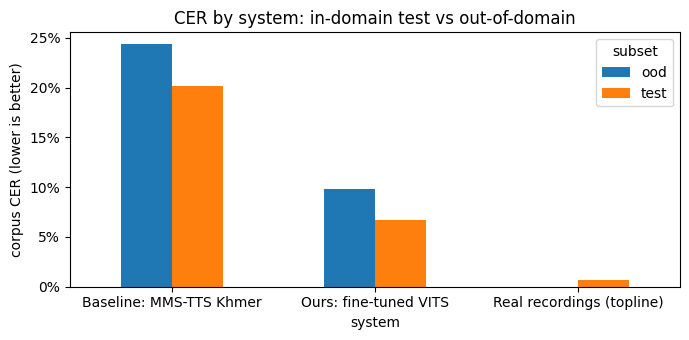

In [19]:
cer_df = load_cer()   # from the transcripts saved by B1
cer_df.to_csv(D['results'] / 'cer_per_utterance.csv', index=False)

summ = []
for (subset, system), g in cer_df.groupby(['subset', 'system']):
    lo, hi = bootstrap_ci(g)
    summ.append(dict(subset=subset, system=SYSTEMS[system], n=len(g), corpus_CER=corpus_cer(g),
                     CI95_low=lo, CI95_high=hi, mean_CER=g.cer.mean(), median_CER=g.cer.median(),
                     failure_rate=(g.cer > 0.5).mean()))
cer_summary = pd.DataFrame(summ)
cer_summary.to_csv(D['results'] / 'cer_summary.csv', index=False)
display(cer_summary.style.format({c: '{:.1%}' for c in ['corpus_CER', 'CI95_low', 'CI95_high', 'mean_CER', 'median_CER', 'failure_rate']}))

ax = cer_summary.pivot(index='system', columns='subset', values='corpus_CER').plot.bar(figsize=(7, 3.5), rot=0)
ax.set_ylabel('corpus CER (lower is better)'); ax.set_title('CER by system: in-domain test vs out-of-domain')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); save_fig('cer_by_system')

---
# Part C. Acoustic metrics (in-domain test set)
- **MCD (mel-cepstral distortion, dB):** how far the synthetic voice's spectrum is from the real recording of the same sentence, after aligning them in time with DTW. Lower is better. It uses the standard definition (the same steps as `pysptk.sp2mc`): mel-cepstrum of the log power spectrum, 24 coefficients, SPTK frequency warping α = 0.42, energy term c0 excluded, computed at **16 kHz for every system**, so MMS (16 kHz audio) is compared fairly. Typical values in TTS papers are about 4–10 dB. The spectrum comes from the STFT rather than the WORLD vocoder, so small differences from published numbers are normal.
- **Duration ratio:** synthetic length ÷ real length after trimming silence. Near 1.0 means a natural speaking rate. Below 0.7 often means skipped words, and above 1.4 often means stretching or babbling.
- **RTF:** compute time ÷ audio length, from the timing log of Part A.

In [ ]:
MCD_SR, MCD_ALPHA, MCD_ORDER = 16000, 0.42, 24   # standard settings for 16 kHz speech

def freqt(c, order=MCD_ORDER, alpha=MCD_ALPHA):
    # SPTK frequency transform: cepstrum (frames x n) -> mel-cepstrum (frames x order+1)
    beta = 1 - alpha ** 2
    g = np.zeros((c.shape[0], order + 1))
    for i in range(c.shape[1] - 1, -1, -1):
        d = g.copy()
        g[:, 0] = c[:, i] + alpha * d[:, 0]
        g[:, 1] = beta * d[:, 0] + alpha * d[:, 1]
        for j in range(2, order + 1):
            g[:, j] = d[:, j - 1] + alpha * (d[:, j] - g[:, j - 1])
    return g

def mel_cep(y):
    # y at MCD_SR -> mel-cepstrum c1..c24 (frames last) and the speech duration in seconds
    y, _ = librosa.effects.trim(y, top_db=35)
    S = np.abs(librosa.stft(y, n_fft=1024, hop_length=160, window='hann'))
    S = np.maximum(S, 1e-5 * S.max())                    # floor, so silent frames do not explode the log
    c = np.fft.irfft(np.log(S ** 2), axis=0)[:40].T      # cepstrum of the log POWER spectrum (as pysptk.sp2mc); first 40 = envelope
    c[:, 0] /= 2
    return freqt(c)[:, 1:].T, len(y) / MCD_SR            # drop c0 (energy), as in the standard MCD

def mcd_dtw(A, B):
    _, wp = librosa.sequence.dtw(X=A, Y=B, metric='euclidean')
    d = A[:, wp[:, 0]] - B[:, wp[:, 1]]
    return float(np.mean(10 / np.log(10) * np.sqrt(2 * np.sum(d ** 2, axis=0))))

acoustic_path = D['results'] / 'acoustic_per_utterance.csv'
rows = []
for _, r in tqdm(test.iterrows(), total=len(test), desc='MCD'):
    ref, ref_dur = mel_cep(load(r.real_wav, sr=MCD_SR))
    for s in ['ours', 'mms']:
        p = wav_path(s, 'test', r.id)
        if not os.path.exists(p): continue
        syn, syn_dur = mel_cep(load(p, sr=MCD_SR))
        rows.append(dict(system=s, id=r.id, topic=r.topic, mcd=mcd_dtw(ref, syn),
                         real_sec=ref_dur, syn_sec=syn_dur, dur_ratio=syn_dur / ref_dur))
acoustic = pd.DataFrame(rows); acoustic.to_csv(acoustic_path, index=False)

rtf = load_rtf()   # from Part A's timing log

ac_summary = acoustic.groupby('system').agg(MCD_mean=('mcd', 'mean'), MCD_sd=('mcd', 'std'),
                                            dur_ratio_median=('dur_ratio', 'median'),
                                            too_short=('dur_ratio', lambda x: (x < 0.7).mean()),
                                            too_long=('dur_ratio', lambda x: (x > 1.4).mean())).join(rtf)
ac_summary.index = ac_summary.index.map(SYSTEMS)
ac_summary.to_csv(D['results'] / 'acoustic_summary.csv')
display(ac_summary.style.format({'MCD_mean': '{:.2f}', 'MCD_sd': '{:.2f}', 'dur_ratio_median': '{:.2f}',
                                 'too_short': '{:.1%}', 'too_long': '{:.1%}', 'RTF': '{:.3f}'}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for s in ['ours', 'mms']:
    g = acoustic[acoustic.system == s]
    ax[0].hist(g.mcd, bins=40, alpha=.6, label=SYSTEMS[s]); ax[1].hist(g.dur_ratio, bins=40, alpha=.6, label=SYSTEMS[s])
ax[0].set_title('MCD per sentence (dB, lower is better)'); ax[1].set_title('Duration ratio (synthetic ÷ real)')
ax[1].axvline(1, c='k', lw=1, ls='--'); ax[0].legend(); save_fig('mcd_duration_hist')

### C1. Spectrogram comparison: real vs ours vs MMS (one sentence)

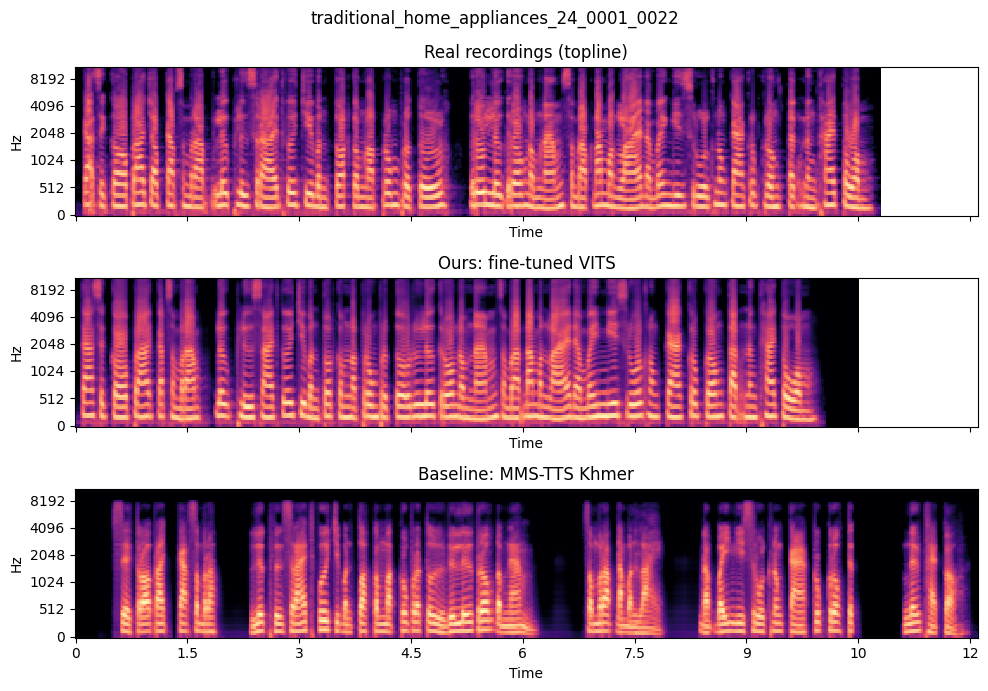

កសិករប្រើចបកាប់សម្រាប់ លើកភ្លឺស្រែធ្វើជាបន្ទាត់កំណត់ព្រំប្រទល់ឬលើករងដំណាំ សម្រាប់ដាំបន្លែ ដើម្បីងាយស្រួលក្នុងការគ្រប់គ្រងទឹក និងថែទាំ។


In [21]:
r = test.sample(1, random_state=3).iloc[0]
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for a, s in zip(ax, ['real', 'ours', 'mms']):
    y = load(wav_path(s, 'test', r.id))
    M = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=EVAL_SR, n_mels=80), ref=np.max)
    librosa.display.specshow(M, sr=EVAL_SR, x_axis='time', y_axis='mel', ax=a); a.set_title(SYSTEMS[s])
fig.suptitle(f'{r.id}'); save_fig('spectrogram_comparison')
print(r.text)

---
# Part D. Mean Opinion Score (MOS)
### D1. Build the blind listening-test package
- **In-domain:** `N_MOS_IN` test sentences (at least one per topic) × 3 systems (real, ours, MMS).
- **Out-of-domain:** every OOD sentence × 2 systems (ours, MMS).
- Every clip is renamed to a random code (`c001.wav`, …) and shuffled, so raters cannot tell which system made it. All clips are normalised to the same loudness (−23 LUFS), so volume does not bias the scores.
- The answer key is saved separately as `_KEY_do_not_share.csv`.

**Send `mos/mos_package.zip` to native Khmer speakers** (aim for 8 or more raters). Each rater fills in `ratings_template.csv` and returns it. Save the returned files in `step4_evaluation/mos/responses/`.

In [22]:
import pyloudnorm as pyln, textwrap
meter = pyln.Meter(EVAL_SR)
(D['mos'] / 'responses').mkdir(parents=True, exist_ok=True)
rated = list((D['mos'] / 'responses').glob('*.csv'))
if rated and (D['mos'] / '_KEY_do_not_share.csv').exists():
    # never reshuffle after raters started: the answer key must keep matching their files
    print(f'ℹ️ {len(rated)} rating file(s) already returned: the listening package is kept unchanged. Go to D2.')
else:

    per_topic = test.groupby('topic', group_keys=False).apply(lambda g: g.sample(1, random_state=SEED))
    rest = test.drop(per_topic.index)
    mos_in = pd.concat([per_topic, rest.sample(max(0, N_MOS_IN - len(per_topic)), random_state=SEED)]).head(N_MOS_IN)

    items = [(s, 'test', r.id, r.text) for _, r in mos_in.iterrows() for s in ['real', 'ours', 'mms']]
    items += [(s, 'ood', r.id, r.text) for _, r in ood.iterrows() for s in ['ours', 'mms']]
    random.Random(SEED).shuffle(items)

    clip_dir = D['mos'] / 'clips'; clip_dir.mkdir(exist_ok=True)
    key = []
    for k, (s, subset, id_, text) in enumerate(tqdm(items, desc='MOS clips'), 1):
        cid = f'c{k:03d}'
        y = load(wav_path(s, subset, id_))
        try: y = pyln.normalize.loudness(y, meter.integrated_loudness(y), -23.0)
        except Exception: pass
        y = y * min(1.0, 0.95 / (np.abs(y).max() + 1e-9))
        sf.write(clip_dir / f'{cid}.wav', y, EVAL_SR, subtype='PCM_16')
        key.append(dict(clip_id=cid, system=s, subset=subset, item_id=id_, text=text))
    key = pd.DataFrame(key); key.to_csv(D['mos'] / '_KEY_do_not_share.csv', index=False)

    pd.DataFrame({'rater_id': '', 'clip_id': key.clip_id, 'naturalness': '', 'intelligibility': ''}) \
      .to_csv(D['mos'] / 'ratings_template.csv', index=False)

    instructions = textwrap.dedent('''\
    Khmer speech listening test (ITM 454, Group 5)
    Use headphones in a quiet room. Listen to each clip (c001.wav, c002.wav, ...) once or twice, in order.
    Write your name or initials in rater_id, and give two scores from 1 to 5 for every clip:

    NATURALNESS: how human-like does the voice sound?
      5 Excellent - completely natural   4 Good - mostly natural
      3 Fair - clearly synthetic but OK  2 Poor - unnatural   1 Bad - very unnatural / robotic

    INTELLIGIBILITY: how easy is it to understand every word?
      5 Every word is clear   4 Almost every word   3 Most words, with effort
      2 Only some words       1 Cannot understand

    Some clips are real recordings and some are computer-generated. Rate each clip on its own.
    Save the file as ratings_<your name>.csv and send it back.
    ''')
    (D['mos'] / 'INSTRUCTIONS.txt').write_text(instructions, encoding='utf-8')

    with zipfile.ZipFile(D['mos'] / 'mos_package.zip', 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(clip_dir.glob('*.wav')): z.write(p, f'clips/{p.name}')
        z.write(D['mos'] / 'ratings_template.csv', 'ratings_template.csv')
        z.write(D['mos'] / 'INSTRUCTIONS.txt', 'INSTRUCTIONS.txt')
    (D['mos'] / 'responses').mkdir(exist_ok=True)
    print(f"{len(key)} clips ->", D['mos'] / 'mos_package.zip')
    display(key.groupby(['subset', 'system']).size().rename('clips').to_frame().T)

MOS clips:   0%|          | 0/65 [00:00<?, ?it/s]

65 clips -> /content/drive/MyDrive/NLPfinalproject/step4_evaluation/mos/mos_package.zip


subset ood      test          
system mms ours  mms ours real
clips   10   10   15   15   15

### D2. Analyse the ratings (run after the raters reply)
For each system, the cell reports the MOS ± 95% confidence interval (t-distribution) for naturalness and intelligibility. It also runs a Mann-Whitney U test of ours vs MMS, because ratings are ordinal.

In [23]:
from scipy import stats
files = sorted((D['mos'] / 'responses').glob('*.csv'))
if not files:
    print('ℹ️ No MOS ratings yet. This is expected until listeners send back their rating files.')
    print('   1) Send', D['mos'] / 'mos_package.zip', 'to native Khmer speakers')
    print('   2) Put each returned CSV in', D['mos'] / 'responses')
    print('   3) Run this cell and Part F again. Until then, Part F leaves the MOS columns empty.')
    mos_summary = None
else:
    key = pd.read_csv(D['mos'] / '_KEY_do_not_share.csv')   # answer key from D1 (also works after a restart)
    resp = pd.concat([pd.read_csv(f).assign(file=f.name) for f in files], ignore_index=True)
    resp['rater_id'] = resp.rater_id.fillna(resp.file).astype(str)
    long = resp.melt(id_vars=['rater_id', 'clip_id'], value_vars=['naturalness', 'intelligibility'],
                     var_name='criterion', value_name='score')
    long['score'] = pd.to_numeric(long.score, errors='coerce')
    bad = long.score.isna() | ~long.score.between(1, 5)
    if bad.any(): print(f'ignored {bad.sum()} empty or invalid scores')
    long = long[~bad].merge(key, on='clip_id')
    long.to_csv(D['results'] / 'mos_ratings_long.csv', index=False)

    def ci95(x): return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
    mos_summary = long.groupby(['subset', 'criterion', 'system']).score.agg(MOS='mean', CI95=ci95, n='size').reset_index()
    mos_summary['raters'] = long.groupby(['subset', 'criterion', 'system']).rater_id.nunique().values
    mos_summary['system'] = mos_summary.system.map(SYSTEMS)
    mos_summary.to_csv(D['results'] / 'mos_summary.csv', index=False)
    display(mos_summary.style.format({'MOS': '{:.2f}', 'CI95': '±{:.2f}'}))

    for (subset, crit), g in long.groupby(['subset', 'criterion']):
        a, b = g[g.system == 'ours'].score, g[g.system == 'mms'].score
        if len(a) and len(b):
            p = stats.mannwhitneyu(a, b).pvalue
            print(f'{subset:4s} {crit:15s} ours {a.mean():.2f} vs MMS {b.mean():.2f}  p = {p:.4f}')

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
    for a, crit in zip(ax, ['naturalness', 'intelligibility']):
        g = mos_summary[mos_summary.criterion == crit]
        piv, err = g.pivot(index='system', columns='subset', values='MOS'), g.pivot(index='system', columns='subset', values='CI95')
        piv.plot.bar(yerr=err, ax=a, rot=0, capsize=3); a.set_title(f'MOS: {crit}'); a.set_ylim(1, 5)
    save_fig('mos')

ℹ️ No MOS ratings yet. This is expected until listeners send back their rating files.
   1) Send /content/drive/MyDrive/NLPfinalproject/step4_evaluation/mos/mos_package.zip to native Khmer speakers
   2) Put each returned CSV in /content/drive/MyDrive/NLPfinalproject/step4_evaluation/mos/responses
   3) Run this cell and Part F again. Until then, Part F leaves the MOS columns empty.


---
# Part E. Error analysis (our model, in-domain test set)
The goal is to find *where* the model fails, and to separate **real TTS errors** from errors the **ASR** would make anyway.

,Real recordings (topline),Ours: fine-tuned VITS,Baseline: MMS-TTS Khmer,sentences
topic,,,,
Etiquettes,0.1%,2.6%,17.0%,35
Greetings,1.0%,4.9%,17.2%,18
Dining,0.5%,5.2%,14.6%,25
Burials,0.2%,5.2%,18.8%,49
Hospitality,0.4%,6.0%,20.6%,46
Local Name,1.4%,6.6%,15.8%,35
Giving Gift,0.7%,6.9%,23.9%,36
Traditional Home Appliances,0.5%,8.5%,22.2%,26
Public Holiday,0.5%,8.6%,21.1%,32


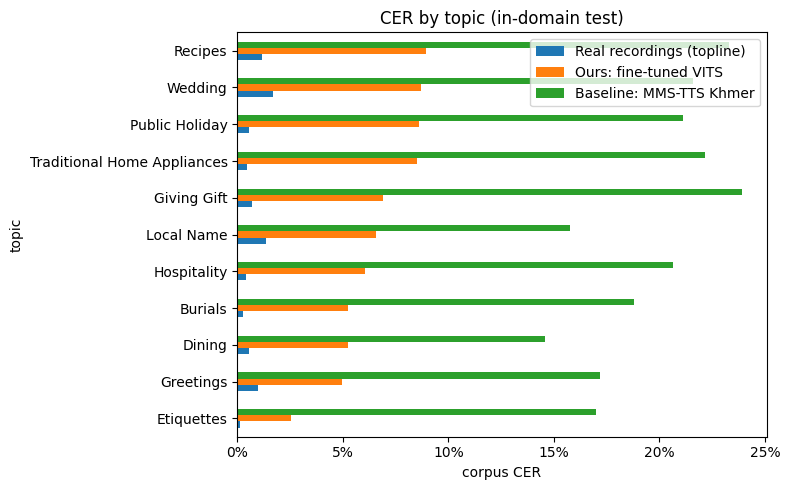

In [24]:
# E1. CER by topic (all tables are rebuilt from the files on Drive, so B2 / Part C need not be in memory)
cer_df, acoustic, ours, ea, by_topic = error_tables()
display(by_topic.style.format({c: '{:.1%}' for c in by_topic.columns if c != 'sentences'}))
ax = by_topic.drop(columns='sentences').plot.barh(figsize=(8, 5)); ax.set_xlabel('corpus CER')
ax.set_title('CER by topic (in-domain test)'); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
save_fig('cer_by_topic')

### E2. Does sentence length matter?

,sentences,CER ours,CER real,CER MMS
length,,,,
<60,29,9.0%,0.5%,24.6%
60–89,118,6.9%,0.9%,19.0%
90–119,129,6.8%,0.9%,20.4%
120–159,96,6.5%,0.6%,20.6%
160+,27,6.0%,0.5%,19.4%


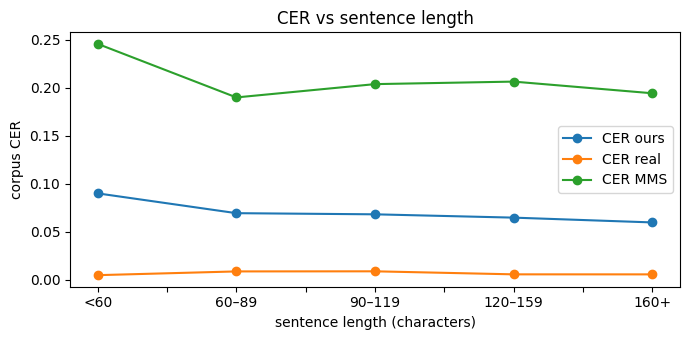

In [25]:
if 'ea' not in globals(): cer_df, acoustic, ours, ea, by_topic = error_tables()
bins = [0, 60, 90, 120, 160, 1000]
labels = ['<60', '60–89', '90–119', '120–159', '160+']
ea['length'] = pd.cut(ea.n_chars, bins=bins, labels=labels, right=False)
by_len = ea.groupby('length').apply(lambda g: pd.Series({
    'sentences': len(g), 'CER ours': g.edits.sum() / g.ref_len.sum(),
    'CER real': (g.cer_real * g.ref_len).sum() / g.ref_len.sum(),
    'CER MMS': (g.cer_mms * g.ref_len).sum() / g.ref_len.sum()}))
display(by_len.style.format({'sentences': '{:.0f}', 'CER ours': '{:.1%}', 'CER real': '{:.1%}', 'CER MMS': '{:.1%}'}))
ax = by_len.drop(columns='sentences').plot(marker='o', figsize=(7, 3.5)); ax.set_xlabel('sentence length (characters)')
ax.set_ylabel('corpus CER'); ax.set_title('CER vs sentence length'); save_fig('cer_by_length')

### E3. TTS errors vs ASR errors
Each sentence gets one of these labels:
- **good:** our CER ≤ 10%
- **ASR-limited:** the ASR already fails on the real recording (real CER > 20%), so this is not the TTS's fault
- **TTS error:** ours is at least 20 points worse than the real recording
- **minor:** everything else

In [26]:
if 'ea' not in globals(): cer_df, acoustic, ours, ea, by_topic = error_tables()
display(ea.category.value_counts().to_frame('sentences').assign(share=lambda d: (d.sentences / d.sentences.sum()).map('{:.1%}'.format)))
ea.reset_index().to_csv(D['results'] / 'error_analysis_per_utterance.csv', index=False)

worst = ea.query("category=='TTS error'").sort_values('delta', ascending=False).head(10)
display(worst[['topic', 'cer', 'cer_real', 'text', 'hyp']].rename(columns={'hyp': 'ASR on ours'}))
for id_, r in worst.head(3).iterrows():
    display(Markdown(f"**{id_}**: CER ours {r.cer:.0%} vs real {r.cer_real:.0%}  \n**input:** {r.text}  \n**heard:** {r.hyp}"))
    display(Audio(wav_path('ours', 'test', id_)))

,sentences,share
category,,
good,297,74.4%
minor,90,22.6%
TTS error,12,3.0%


,topic,cer,cer_real,text,ASR on ours
id,,,,,
recipes_70_0001_0007,Recipes,0.393443,0.016393,គេប្រើ ប្រេងសណ្ដែកសៀង ដើម្បីបំពងនំប៉ោងឱ្យឆ្ងាញ់ និងមានពណ៌រលោងល្អ។,ទៀបផ្លាវព្រះសណ្តែកសៀន ដើម្បីបំពងៗឱ្យឆ្ងាញ់ និងមានពណ៌លង់ដ្រូង
traditional_home_appliances_24_0001_0008,Traditional Home Appliances,0.313725,0.000000,រីឯដងចប ឬហៅថា ដៃចប គឺជាដងឈើ ឬដែកវែង ដែលភ្ជាប់ទៅនឹងផ្លែចប។,រីឯដង្ហុះបុរិកហៅថា បាញ់ចប់ គឺជាដងឈើ ឬដៃវែងដែលភ្ជាប់ទៅនឹងផ្លែចប់
recipes_26_0004_0004,Recipes,0.246154,0.000000,ក្រៅពីផ្តល់ពណ៌ រមៀតក៏បន្ថែមរសជាតិ និងក្លិនឈ្ងុយប្លែកក្នុងម្ហូបផងដែរ។,ត្រូវពីត្រាប់ពណ៌ រមៀតប៉ុល បន្ថែមរសជាតិ និងក្លិនឈ្ងុយប្លែកខ្នងម៉ូផងដែរ
giving_gift_07_0001_0025,Giving Gift,0.260417,0.020833,ល្ខោនស្បែកធំ គឺជាល្ខោនអាយ៉ងស្បែកដ៏ធំ ដែលត្រូវបានចុះបញ្ជីជាបេតិកភណ្ឌវប្បធម៌អរូបីរបស់អង្គការយូណេស្កូ។,ល្ខោនស្បែកធំ គឺជាល្ខោនអាយ៉ងស្បែកដ៏ធំដែលត្រូវបានចង់បញ្ជីជាពេទ្យក៏ផុនវប្បធម៌រូបរបស់អំកាយយួន Netflix
wedding_05_0001_0020,Wedding,0.246914,0.012346,គេក៍មានការបម្រើ ជាភេសជ្ជៈ ដែលមានដូចជា កាហ្វេទឹកដោះគោទឹកកក តែក្រូចឆ្មារ តែទឹកដោះគោ ជាដើម។,ពាសគមមានការបម្រើជាភេសជ្ជៈដែលមានដូចជា ក៏សីតុណ្ហភ័ក្តិទឹកកក តែក្រូចឆ្មារ តែទឹកបោះគោជាដើម
etiquettes_13_0001_0032,Etiquettes,0.230769,0.000000,កាយវិការនេះជួយឱ្យសិស្សានុសិស្សមានអាកប្បកិរិយាល្អ និងចេះគោរពអ្នកដទៃ។,កាយវិការនេះជួយឱ្យសិស្សសន្សំសម្លៀកបំពាក់រយៈល្អ និងចេះគោរពអ្នកដទៃ
wedding_05_0001_0024,Wedding,0.260000,0.040000,បន្ទាប់ពីនោះ ដល់ពេលល្ងាចគេឲ្យយើងនូវស៊ុបក្តាមដំបូងគេ។,បន្ទាប់ពីនោះ ដល់ពេលល្ងាច ទាយឱ្យយើងនៅសុខដើមដំបូងពេល
recipes_20_0001_0010,Recipes,0.233645,0.018692,ចំណែកឯគ្រឿងបន្លែផ្សេងទៀត ហាន់សណ្ដែកកួរជាកង់ៗ ហាន់ប៉េងប៉ោះជាចំណិតៗ ត្រប់ស្រួយកាត់ជាដុំល្មមៗ ជីរណាហាន់មួយចង្អុលដៃ។,ចំណែកឯគ្រឿងបន្លែផ្សេងទៀត ហាន់សម្តែងតួជាខោងកោង ហាន់ប៉េងប៉ោះជាចំណុចទនេដ្ឋស្រប ស្រួយកាត់ជាដុំល្មម និងជារណាហានមួយចង្អុលដៃ
traditional_home_appliances_24_0001_0004,Traditional Home Appliances,0.214286,0.000000,វាត្រូវមានផ្នែកសំខាន់ៗពីរគឺ ផ្លែនិងដងរបស់ចប។,វាត្រូវមានថ្នាយសំខាន់ខ័ណ្ឌពីរគឺ ផ្លែ និងដងរបស់ចប់


**recipes_70_0001_0007**: CER ours 39% vs real 2%  
**input:** គេប្រើ ប្រេងសណ្ដែកសៀង ដើម្បីបំពងនំប៉ោងឱ្យឆ្ងាញ់ និងមានពណ៌រលោងល្អ។  
**heard:** ទៀបផ្លាវព្រះសណ្តែកសៀន ដើម្បីបំពងៗឱ្យឆ្ងាញ់ និងមានពណ៌លង់ដ្រូង

**traditional_home_appliances_24_0001_0008**: CER ours 31% vs real 0%  
**input:** រីឯដងចប ឬហៅថា ដៃចប គឺជាដងឈើ ឬដែកវែង ដែលភ្ជាប់ទៅនឹងផ្លែចប។  
**heard:** រីឯដង្ហុះបុរិកហៅថា បាញ់ចប់ គឺជាដងឈើ ឬដៃវែងដែលភ្ជាប់ទៅនឹងផ្លែចប់

**recipes_26_0004_0004**: CER ours 25% vs real 0%  
**input:** ក្រៅពីផ្តល់ពណ៌ រមៀតក៏បន្ថែមរសជាតិ និងក្លិនឈ្ងុយប្លែកក្នុងម្ហូបផងដែរ។  
**heard:** ត្រូវពីត្រាប់ពណ៌ រមៀតប៉ុល បន្ថែមរសជាតិ និងក្លិនឈ្ងុយប្លែកខ្នងម៉ូផងដែរ

### E4. Which Khmer characters go wrong?
Every edit between the input text and what the ASR heard is counted: *substitutions* (A heard as B), *deletions* (A missing) and *insertions* (extra B). The per-character error rate shows which characters the model struggles with, for example subscript consonants (coeng `្`) or vowel signs.

In [27]:
if 'ea' not in globals(): cer_df, acoustic, ours, ea, by_topic = error_tables()
from collections import Counter
sub, dele, ins, ref_count = Counter(), Counter(), Counter(), Counter()
for _, r in ours.iterrows():
    a, b = norm_cer(r.text), norm_cer(r.hyp); ref_count.update(a)
    for op in Levenshtein.editops(a, b):
        if op.tag == 'replace': sub[(a[op.src_pos], b[op.dest_pos])] += 1
        elif op.tag == 'delete': dele[a[op.src_pos]] += 1
        else: ins[b[op.dest_pos]] += 1

def nm(c): return f"{c} ({unicodedata.name(c, '?').replace('KHMER ', '').lower()})"
display(pd.DataFrame([(nm(x), nm(y), n) for (x, y), n in sub.most_common(15)], columns=['input', 'heard as', 'count']))
display(pd.DataFrame([(nm(c), n) for c, n in dele.most_common(10)], columns=['deleted', 'count']).join(
        pd.DataFrame([(nm(c), n) for c, n in ins.most_common(10)], columns=['inserted', 'count '])))

err = Counter({c: dele[c] + sum(n for (x, _), n in sub.items() if x == c) for c in ref_count})
char_er = pd.DataFrame([(nm(c), ref_count[c], err[c], err[c] / ref_count[c]) for c in ref_count if ref_count[c] >= 50],
                       columns=['character', 'occurrences', 'errors', 'error_rate']).sort_values('error_rate', ascending=False)
char_er.to_csv(D['results'] / 'character_error_rates.csv', index=False)
display(char_er.head(15).style.format({'error_rate': '{:.1%}'}))

,input,heard as,count
0,ដ (letter da),ត (letter ta),39
1,ក (letter ka),ត (letter ta),23
2,ិ (vowel sign i),ឹ (vowel sign y),17
3,ប (letter ba),ត (letter ta),15
4,ុ (vowel sign u),ប (letter ba),15
5,្ (sign coeng),ា (vowel sign aa),14
6,ា (vowel sign aa),ី (vowel sign ii),12
7,ល (letter lo),រ (letter ro),12
8,អ (letter qa),ឱ (independent vowel qoo type one),10
9,ទ (letter to),ត (letter ta),10


,deleted,count,inserted,count
0,្ (sign coeng),53,្ (sign coeng),75
1,រ (letter ro),37,រ (letter ro),51
2,់ (sign bantoc),36,ា (vowel sign aa),47
3,ក (letter ka),31,ត (letter ta),36
4,ត (letter ta),22,ុ (vowel sign u),34
5,ា (vowel sign aa),19,ប (letter ba),34
6,ុ (vowel sign u),16,ទ (letter to),33
7,ៗ (sign lek too),14,ន (letter no),32
8,ប (letter ba),14,់ (sign bantoc),29
9,ម (letter mo),14,ម (letter mo),28


,character,occurrences,errors,error_rate
32,ៗ (sign lek too),75,47,62.7%
53,៍ (sign toandakhiat),51,11,21.6%
54,័ (sign samyok sannya),55,8,14.5%
47,ឬ (independent vowel ryy),133,19,14.3%
36,ោ (vowel sign oo),399,47,11.8%
44,៉ (sign muusikatoan),171,20,11.7%
4,ុ (vowel sign u),698,72,10.3%
22,ខ (letter kha),370,35,9.5%
37,ះ (sign reahmuk),392,34,8.7%
43,ៈ (sign yuukaleapintu),73,6,8.2%


### E5. Speaking-rate problems (skipped or stretched speech)

In [28]:
if 'ea' not in globals(): cer_df, acoustic, ours, ea, by_topic = error_tables()
if 'dur_ratio' in ea:
    odd = ea[(ea.dur_ratio < 0.7) | (ea.dur_ratio > 1.4)].sort_values('dur_ratio')
    print(f"{len(odd)} of {len(ea)} sentences have an unusual length (ratio < 0.7 or > 1.4)")
    display(odd[['topic', 'dur_ratio', 'cer', 'text']].head(10))
    print('correlation between |duration ratio − 1| and CER:', round(np.corrcoef((ea.dur_ratio - 1).abs(), ea.cer)[0, 1], 3))
else:
    print('No duration data yet: run Part C, then this cell again.')

0 of 399 sentences have an unusual length (ratio < 0.7 or > 1.4)


,topic,dur_ratio,cer,text
id,,,,


correlation between |duration ratio − 1| and CER: 0.128


---
# Part F. Summary for the report
The cell builds one table with every metric (saved as `results/summary.csv` and `summary.md`) and writes the main findings as sentences.

In [ ]:
# everything is reloaded from Drive, so Part F works even if earlier cells were skipped
cer_df, acoustic, ours, ea, by_topic = error_tables()
rtf, mos_summary = load_rtf(), load_mos()   # mos_summary is None until listener ratings exist

def get_cer(subset, s):
    g = cer_df[(cer_df.subset == subset) & (cer_df.system == s)]; return corpus_cer(g) if len(g) else np.nan
def get_mos(subset, crit, s):
    if mos_summary is None: return np.nan
    g = mos_summary[(mos_summary.subset == subset) & (mos_summary.criterion == crit) & (mos_summary.system == SYSTEMS[s])]
    return g.MOS.iloc[0] if len(g) else np.nan

acs = acoustic.groupby('system').agg(mcd=('mcd', 'mean'), dr=('dur_ratio', 'median')) if len(acoustic) else pd.DataFrame(columns=['mcd', 'dr'])
table = pd.DataFrame([{
    'System': SYSTEMS[s],
    'CER test ↓': get_cer('test', s), 'CER OOD ↓': get_cer('ood', s),
    'MCD (dB) ↓': acs.mcd.get(s, np.nan), 'Duration ratio': acs.dr.get(s, np.nan), 'RTF ↓': rtf.get(s, np.nan),
    'MOS-N test ↑': get_mos('test', 'naturalness', s), 'MOS-I test ↑': get_mos('test', 'intelligibility', s),
    'MOS-N OOD ↑': get_mos('ood', 'naturalness', s), 'MOS-I OOD ↑': get_mos('ood', 'intelligibility', s),
} for s in ['real', 'ours', 'mms']])
table.to_csv(D['results'] / 'summary.csv', index=False)

fmt = table.copy()
for c in fmt.columns[1:]:
    fmt[c] = fmt[c].map(lambda v: '–' if pd.isna(v) else (f'{v:.1%}' if 'CER' in c else f'{v:.2f}'))
md_table = fmt.to_markdown(index=False); (D['results'] / 'summary.md').write_text(md_table, encoding='utf-8')
display(Markdown(md_table))

c_real, c_ours, c_mms = get_cer('test', 'real'), get_cer('test', 'ours'), get_cer('test', 'mms')
c_ood = get_cer('ood', 'ours'); cats = ea.category.value_counts(normalize=True)
worst_topic, best_topic = by_topic[SYSTEMS['ours']].idxmax(), by_topic[SYSTEMS['ours']].idxmin()
findings = [
    f"On the {len(test)} unseen test sentences our VITS reaches a CER of {c_ours:.1%}, against {c_real:.1%} for the real recordings (the ASR's own error) and {c_mms:.1%} for the MMS-TTS baseline.",
    f"Our model is {'better' if c_ours < c_mms else 'worse'} than the baseline by {abs(c_mms - c_ours) * 100:.1f} CER points; the gap to real speech is {(c_ours - c_real) * 100:.1f} points.",
    f"Out of domain, CER is {c_ood:.1%} ({(c_ood - c_ours) * 100:+.1f} points vs in-domain)" + (", which matches the domain limitation expected in the proposal." if c_ood > c_ours else ", so the model generalises beyond the training topics."),
    f"{cats.get('good', 0):.0%} of test sentences are near-perfect (CER ≤ 10%), {cats.get('TTS error', 0):.0%} are clear TTS errors and {cats.get('ASR-limited', 0):.0%} are limited by the ASR itself.",
    f"The hardest topic is {worst_topic} and the easiest is {best_topic}.",
]
if len(acs):
    findings.append(f"Mean MCD: ours {acs.mcd.get('ours', np.nan):.2f} dB vs MMS {acs.mcd.get('mms', np.nan):.2f} dB; median duration ratio of ours is {acs.dr.get('ours', np.nan):.2f}; RTF {rtf.get('ours', np.nan):.3f}.")
else:
    findings.append("MCD / duration ratio: not computed yet (run Part C, then this cell again).")
if mos_summary is None:
    findings.append("MOS: listener ratings not collected yet (send mos/mos_package.zip to raters, then run D2 and this cell again).")
else:
    findings.append(f"Listeners gave our model a naturalness MOS of {get_mos('test', 'naturalness', 'ours'):.2f} (real {get_mos('test', 'naturalness', 'real'):.2f}, MMS {get_mos('test', 'naturalness', 'mms'):.2f}).")
(D['results'] / 'findings.txt').write_text('\n'.join(findings), encoding='utf-8')
display(Markdown('\n'.join(f'- {f}' for f in findings)))
print('\nAll results are in', EVAL_DIR)